In [0]:
import pandas as pd

In [0]:
spotify_user_behavior=spark.table("workspace.spotify.spotify_user_behavior").toPandas()
spotify_user_demo=spark.table("workspace.spotify.spotify_user_demo").toPandas()

In [0]:
print("===Shape Check===")
print("User Behavior Shape     :",spotify_user_behavior.shape)
print("User Demographics Shape :",spotify_user_demo.shape)

===Shape Check===
User Behavior Shape     : (108000, 26)
User Demographics Shape : (108000, 6)


In [0]:
n_user_behavior = spotify_user_behavior["user_id"].nunique()
n_user_demo=spotify_user_demo["user_id"].nunique()
print("Unique User_id in behavior :",n_user_behavior)
print("Unique User_id in Demo       :",n_user_demo)

Unique User_id in behavior : 108000
Unique User_id in Demo       : 108000


In [0]:
#duplicate checks
dup_behavior = spotify_user_behavior["user_id"].duplicated().sum()
dup_demo= spotify_user_demo["user_id"].duplicated().sum()
print("Duplicate User_id in behavior :",dup_behavior)
print("Duplicate User_id in demo     :",dup_demo)

Duplicate User_id in behavior : 0
Duplicate User_id in demo     : 0


In [0]:
#User overlap checks
behavior_set=set(spotify_user_behavior["user_id"])
demo_set=set(spotify_user_demo["user_id"])
print("User in behavior but not in demo :", len(behavior_set - demo_set))
print("User in demo but not in behavior :",len(demo_set-behavior_set))

User in behavior but not in demo : 0
User in demo but not in behavior : 0


In [0]:
print("\n--- user behavior info---")
spotify_user_behavior.info()

print("\n--- user demo info---")
spotify_user_demo.info()


--- user behavior info---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108000 entries, 0 to 107999
Data columns (total 26 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   user_id                           108000 non-null  int64  
 1   daily_listening_minutes           108000 non-null  object 
 2   sessions_per_day                  108000 non-null  int64  
 3   days_active_last_30               108000 non-null  object 
 4   avg_session_minutes               108000 non-null  object 
 5   skip_rate                         108000 non-null  float64
 6   liked_songs_pct                   108000 non-null  object 
 7   ads_skipped_pct                   108000 non-null  object 
 8   playlists_followed                108000 non-null  int64  
 9   artists_followed                  108000 non-null  int64  
 10  genre_diversity_score             108000 non-null  object 
 11  mean_danceability        

In [0]:
def fill_rate(df : pd.DataFrame) -> pd.DataFrame:
    out = (
        df.isna()
          .mean()
          .mul(100)
          .round(2)
          .sort_values()
          .reset_index()

    )
    out.columns= ["column", "missing_pct"]
    out["fill_rate_pct"] = (100 - out["missing_pct"]).round(2)
    return out 
print("\n --- fill rate : user behavior ---")
print(fill_rate(spotify_user_behavior).to_string(index=False))   
print("\n --- fill rate : user demo ---")
print(fill_rate(spotify_user_demo).to_string(index=False))   



 --- fill rate : user behavior ---
                          column  missing_pct  fill_rate_pct
                         user_id          0.0          100.0
median_gap_minutes_between_plays          0.0          100.0
              repeat_artist_rate          0.0          100.0
               repeat_track_rate          0.0          100.0
                       std_tempo          0.0          100.0
                     std_valence          0.0          100.0
                      std_energy          0.0          100.0
                      mean_tempo          0.0          100.0
           mean_instrumentalness          0.0          100.0
                mean_speechiness          0.0          100.0
               mean_acousticness          0.0          100.0
                    mean_valence          0.0          100.0
                     mean_energy          0.0          100.0
               mean_danceability          0.0          100.0
           genre_diversity_score          0.0    

In [0]:
print(spotify_user_demo.shape)

(108000, 6)


In [0]:
print(spotify_user_demo.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108000 entries, 0 to 107999
Data columns (total 6 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   user_id                     108000 non-null  int64 
 1   age                         108000 non-null  object
 2   country                     108000 non-null  object
 3   city_tier                   108000 non-null  int64 
 4   device_type                 108000 non-null  object
 5   subscription_tenure_months  108000 non-null  object
dtypes: int64(2), object(4)
memory usage: 4.9+ MB
None


In [0]:
print("user id Data Type:", spotify_user_demo["user_id"].dtype)
print("age:", spotify_user_demo["age"].dtype)
print("country:",spotify_user_demo["country"].dtype)
print("city tier wise Datatype:",spotify_user_demo["city_tier"].dtype)
print("device type ",spotify_user_demo["device_type"].dtype)
print("subscription tenure in months",spotify_user_demo["subscription_tenure_months"].dtype)

user id Data Type: int64
age: object
country: object
city tier wise Datatype: int64
device type  object
subscription tenure in months object


In [0]:
print(spotify_user_demo["user_id"].nunique())

108000


In [0]:
data_dictionary = pd.DataFrame({"column_name": spotify_user_demo.columns})

In [0]:
print(data_dictionary.to_string(index=True))
print(spotify_user_demo["user_id"].nunique())
print(spotify_user_demo["age"].nunique())
print(spotify_user_demo["age"].isnull().sum())
print(spotify_user_demo.isnull().sum())
print(spotify_user_demo["age"].count())
print(spotify_user_demo["age"].value_counts())
print(spotify_user_demo["country"].value_counts())
print(spotify_user_demo["subscription_tenure_months"].value_counts())

                  column_name
0                     user_id
1                         age
2                     country
3                   city_tier
4                 device_type
5  subscription_tenure_months
108000
99327
0
user_id                       0
age                           0
country                       0
city_tier                     0
device_type                   0
subscription_tenure_months    0
dtype: int64
108000
age
18.000000000000000    8670
70.000000000000000       5
37.662132059412286       1
44.293016220636574       1
29.248413264314916       1
                      ... 
29.452191383769737       1
32.008336009085420       1
37.828846161419630       1
29.551164667026300       1
21.865759676111360       1
Name: count, Length: 99327, dtype: int64
country
US    37830
IN    27085
UK    16184
DE    16138
BR    10763
Name: count, dtype: int64
subscription_tenure_months
1.0000000000000000      5793
120.0000000000000000     116
11.3526983494597180        1
11.3230015531

In [0]:
data_dictionary2=pd.DataFrame({"column_name":spotify_user_behavior.columns})

In [0]:
print(data_dictionary2.to_string(index=False))

                     column_name
                         user_id
         daily_listening_minutes
                sessions_per_day
             days_active_last_30
             avg_session_minutes
                       skip_rate
                 liked_songs_pct
                 ads_skipped_pct
              playlists_followed
                artists_followed
           genre_diversity_score
               mean_danceability
                     mean_energy
                    mean_valence
               mean_acousticness
                mean_speechiness
           mean_instrumentalness
                      mean_tempo
                      std_energy
                     std_valence
                       std_tempo
               repeat_track_rate
              repeat_artist_rate
median_gap_minutes_between_plays
           mean_track_popularity
       pct_top_popularity_tracks


In [0]:
print(spotify_user_behavior["user_id"].nunique())
print(spotify_user_behavior["user_id"].duplicated().sum())
print(spotify_user_behavior["user_id"].value_counts())
print(spotify_user_behavior["user_id"].unique())

108000
0
user_id
1         1
71984     1
72008     1
72007     1
72006     1
         ..
35997     1
35996     1
35995     1
35994     1
108000    1
Name: count, Length: 108000, dtype: int64
[     1      2      3 ... 107998 107999 108000]


In [0]:
print(spotify_user_behavior["daily_listening_minutes"].nunique())
print(spotify_user_behavior["daily_listening_minutes"].value_counts())
print(spotify_user_behavior["daily_listening_minutes"].duplicated().sum())

108000
daily_listening_minutes
27.8600331451566240     1
20.8874470510625400     1
110.5922098868772000    1
15.4755246565346190     1
35.4783537246075800     1
                       ..
24.2694112754627550     1
52.4572520398053040     1
8.5840703021350200      1
20.9498551866610080     1
18.2229623431568760     1
Name: count, Length: 108000, dtype: int64
0


In [0]:
print(spotify_user_behavior[data_dictionary2].value_counts())
print(spotify_user_behavior["sessions_per_day"].value_counts())
print(spotify_user_behavior["sessions_per_day"].duplicated().value_counts())
print(spotify_user_behavior["sessions_per_day"].unique())
print(spotify_user_behavior["sessions_per_day"].nunique())

Series([], Name: count, dtype: int64)
sessions_per_day
1     87597
2     12889
3      4538
4      1707
5       731
6       275
7       126
8        64
9        36
10       15
11       11
12        4
15        3
13        2
14        2
Name: count, dtype: int64
sessions_per_day
True     107985
False        15
Name: count, dtype: int64
[ 1  3  2  4  5  6  8  9  7 10 13 12 11 14 15]
15


In [0]:
#range
import numpy as np
print("/n---Describe: User Behavior(numeric)---")
print(spotify_user_behavior.drop(columns=["user_id"]).describe().T.round(3).to_string())

print("/n---Describe:User Demo(numeric)---")
demo_numeric = spotify_user_demo.select_dtypes(include=[np.number])
if demo_numeric.shape[1]>0:
    print(demo_numeric.describe().T.round(3).to_string())
else:
    print("no numeric columns found in demo beside user_id(if any).")

/n---Describe: User Behavior(numeric)---
                       count    mean     std    min    25%    50%    75%    max
sessions_per_day    108000.0   1.308   0.798  1.000  1.000  1.000  1.000   15.0
skip_rate           108000.0   0.326   0.179  0.001  0.187  0.306  0.442    1.0
playlists_followed  108000.0   9.165  42.990  1.000  1.000  1.000  3.000  500.0
artists_followed    108000.0  15.969  77.937  1.000  1.000  2.000  4.000  800.0
repeat_track_rate   108000.0   0.347   0.180  0.001  0.207  0.327  0.468    1.0
/n---Describe:User Demo(numeric)---
              count       mean        std  min       25%      50%       75%       max
user_id    108000.0  54000.500  31177.059  1.0  27000.75  54000.5  81000.25  108000.0
city_tier  108000.0      1.848      0.792  1.0      1.00      2.0      2.00       3.0


In [0]:
#range
import numpy as np
print("/n---Describe: User Behavior(numeric)---")
print(spotify_user_behavior.drop(columns=["user_id"]).describe().round(3))

print("/n---Describe:User Demo(numeric)---")
demo_numeric = spotify_user_demo.select_dtypes(include=[np.number])
if demo_numeric.shape[1]>0:
    print(demo_numeric.describe().T.round(3).to_string())
else:
    print("no numeric columns found in demo beside user_id(if any).")


/n---Describe: User Behavior(numeric)---
       sessions_per_day   skip_rate  ...  artists_followed  repeat_track_rate
count        108000.000  108000.000  ...        108000.000         108000.000
mean              1.308       0.326  ...            15.969              0.347
std               0.798       0.179  ...            77.937              0.180
min               1.000       0.001  ...             1.000              0.001
25%               1.000       0.187  ...             1.000              0.207
50%               1.000       0.306  ...             2.000              0.327
75%               1.000       0.442  ...             4.000              0.468
max              15.000       1.000  ...           800.000              1.000

[8 rows x 5 columns]
/n---Describe:User Demo(numeric)---
              count       mean        std  min       25%      50%       75%       max
user_id    108000.0  54000.500  31177.059  1.0  27000.75  54000.5  81000.25  108000.0
city_tier  108000.0      1.

In [0]:
#range
import numpy as np
print("/n---Describe: User Behavior(numeric)---")
print(spotify_user_behavior.drop(columns=["user_id"]).describe().T.round(3).to_string())

print("/n---Describe:User Demo(numeric)---")
demo_numeric = spotify_user_demo.select_dtypes(include=[np.number])
if demo_numeric.shape[1]>0:
    print(demo_numeric.describe().T.round(3).to_string())
else:
    print("no numeric columns found in demo beside user_id(if any).")

/n---Describe: User Behavior(numeric)---
                       count    mean     std    min    25%    50%    75%    max
sessions_per_day    108000.0   1.308   0.798  1.000  1.000  1.000  1.000   15.0
skip_rate           108000.0   0.326   0.179  0.001  0.187  0.306  0.442    1.0
playlists_followed  108000.0   9.165  42.990  1.000  1.000  1.000  3.000  500.0
artists_followed    108000.0  15.969  77.937  1.000  1.000  2.000  4.000  800.0
repeat_track_rate   108000.0   0.347   0.180  0.001  0.207  0.327  0.468    1.0
/n---Describe:User Demo(numeric)---
              count       mean        std  min       25%      50%       75%       max
user_id    108000.0  54000.500  31177.059  1.0  27000.75  54000.5  81000.25  108000.0
city_tier  108000.0      1.848      0.792  1.0      1.00      2.0      2.00       3.0


In [0]:
issues=[]
#Helper to add issue rows 
def add_issue(table,col,issue,count):
    issues.append({"table":table,"column":col,"issue":issue,"rows_affected":int(count)})
#Behavior expected ranges
behavior_rules= {
    "daily_listening_minutes":(0,None),"sessions_per_day":(0,None),
    "days_active_last_30":(0,None),"avg_session_minutes":(0,None),
    "skip_rate":(0,1),"liked_songs_pct":(0,1),"ads_skipped_pct":(0,1),
    "genre_diversity_score":(0,1),"mean_danceability":(0,1),
    "mean_energy":(0,1),"mean_valence":(0,1),"mean_acousticness":(0,1),
    "mean_speechiness":(0,1),"mean_instrumentalness":(0.1),"mean_tempo":(0,None),
    "std_energy":(0,None),"std_valence":(0,None),"std_tempo":(0,None),
    "repeat_track_rate":(0,1),"repeat_artist_rate":(0,1),
    "median_gap_minutes_between_plays":(0,None),
    "mean_track_popularity":(0,100),"pct_top_popularity_tracks":(0,1)}

In [0]:
behavior_cols = spotify_user_behavior.columns
for col, bounds in behavior_rules.items():
    if col in behavior_cols:
        s = spotify_user_behavior[col]
        # Ensure bounds is a tuple
        if not isinstance(bounds, tuple):
            bounds = (bounds, None)
        lo, hi = bounds if len(bounds) == 2 else (bounds[0], None)
        if lo is not None:
            bad = (s < lo).sum()
            if bad > 0:
                add_issue("spotify_user_behavior", col, f"value < {lo}", bad)
        if hi is not None:
            bad = (s > hi).sum()
            if bad > 0:
                add_issue("spotify_user_behavior", col, f"value > {hi}", bad)

In [0]:
numeric_cols =(
    spotify_user_behavior
    .drop(columns=["user_id"])
    .columns
    .tolist()

)
print("Number of numeric features:",len(numeric_cols))
print(numeric_cols)

Number of numeric features: 25
['daily_listening_minutes', 'sessions_per_day', 'days_active_last_30', 'avg_session_minutes', 'skip_rate', 'liked_songs_pct', 'ads_skipped_pct', 'playlists_followed', 'artists_followed', 'genre_diversity_score', 'mean_danceability', 'mean_energy', 'mean_valence', 'mean_acousticness', 'mean_speechiness', 'mean_instrumentalness', 'mean_tempo', 'std_energy', 'std_valence', 'std_tempo', 'repeat_track_rate', 'repeat_artist_rate', 'median_gap_minutes_between_plays', 'mean_track_popularity', 'pct_top_popularity_tracks']


In [0]:
summary=(
    spotify_user_behavior[numeric_cols]
    .describe()
    .T
    .loc[:,["mean","std","min",
         "25%","50%","75%","max"]]
    .round(3)
)
summary["mean_minus_median"]=(
    summary["mean"]-summary["50%"]
).round(3)
summary.sort_values(
    "mean_minus_median",ascending=False
).head(10)
print("\nTop 10 features by mean-median(skew indicator):")
print(
    summary
    .sort_values("mean_minus_median",ascending=False)
    .head(10)
)



Top 10 features by mean-median(skew indicator):
                      mean     std    min  ...    75%    max  mean_minus_median
artists_followed    15.969  77.937  1.000  ...  4.000  800.0             13.969
playlists_followed   9.165  42.990  1.000  ...  3.000  500.0              8.165
sessions_per_day     1.308   0.798  1.000  ...  1.000   15.0              0.308
skip_rate            0.326   0.179  0.001  ...  0.442    1.0              0.020
repeat_track_rate    0.347   0.180  0.001  ...  0.468    1.0              0.020

[5 rows x 8 columns]


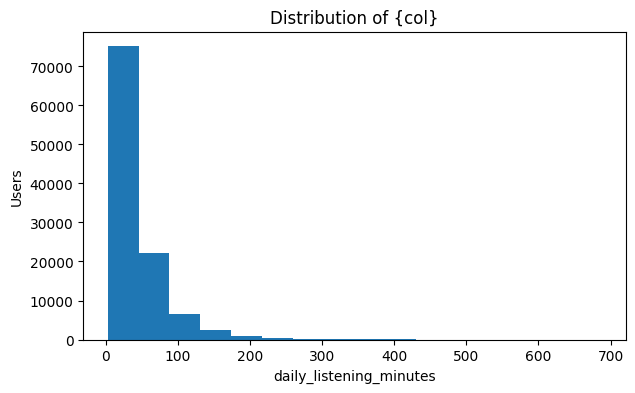

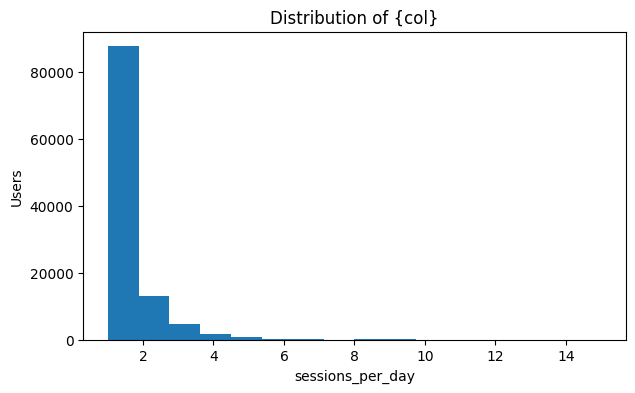

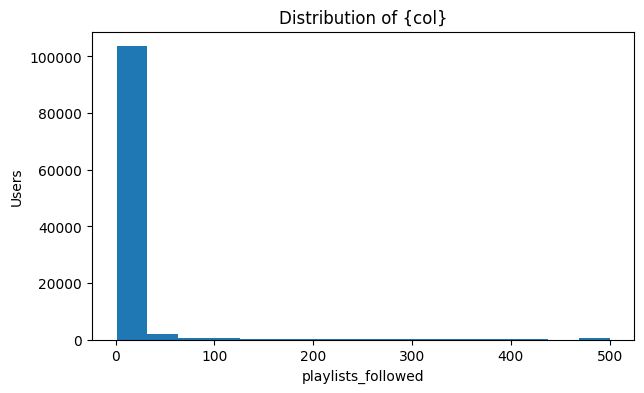

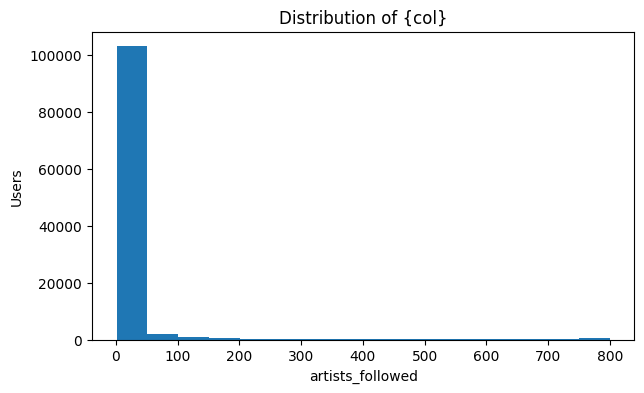

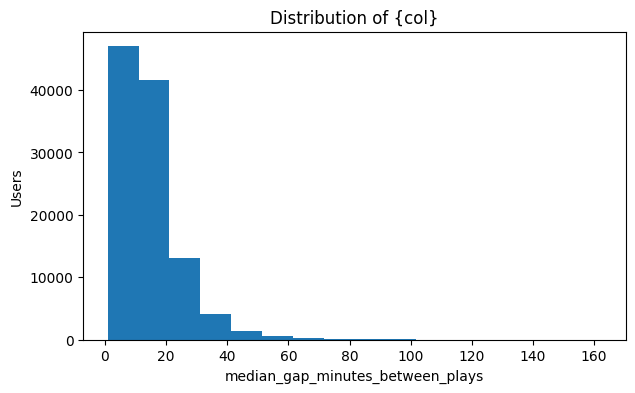

In [0]:
import matplotlib.pyplot as plt
features_to_plot=[
    "daily_listening_minutes",
    "sessions_per_day",
    "playlists_followed",
    "artists_followed",
    "median_gap_minutes_between_plays"
]

for col in features_to_plot:
    plt.figure(figsize=(7,4))
    plt.hist(spotify_user_behavior[col],
             bins=16)
    plt.title("Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Users")
    plt.show()

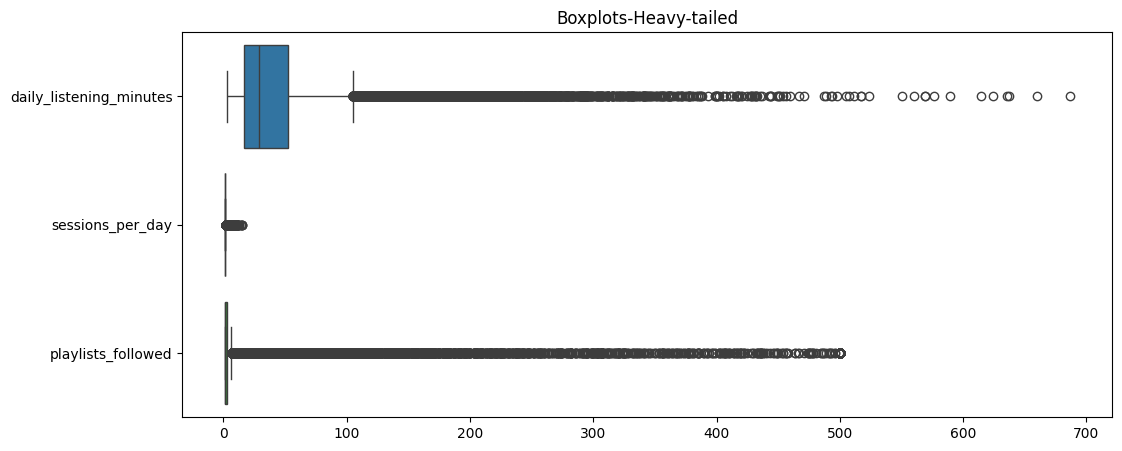

In [0]:
import seaborn as sns
plt.figure(figsize=(12,5))
sns.boxplot(
    data=spotify_user_behavior[
        [
            "daily_listening_minutes",
            "sessions_per_day",
            "playlists_followed"
        ]
    ],
    orient="h"
)
plt.title("Boxplots-Heavy-tailed")
plt.show()

In [0]:
scale_check=(
    summary[["min","max","std"]]
    .sort_values("max",ascending=False)
)

print("\nFeature scale comparision:")
print(scale_check.head(10))


Feature scale comparision:
                      min    max     std
artists_followed    1.000  800.0  77.937
playlists_followed  1.000  500.0  42.990
sessions_per_day    1.000   15.0   0.798
skip_rate           0.001    1.0   0.179
repeat_track_rate   0.001    1.0   0.180


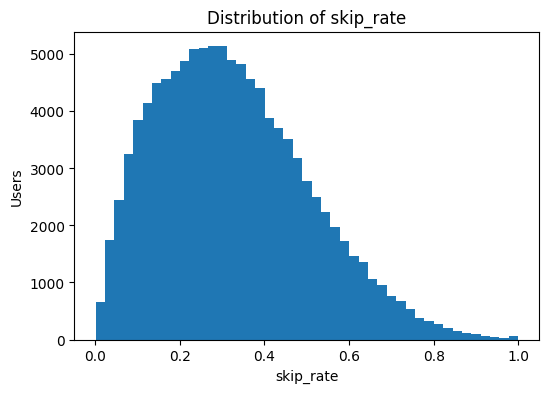

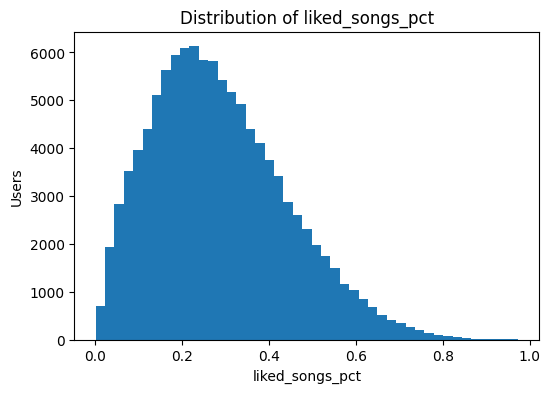

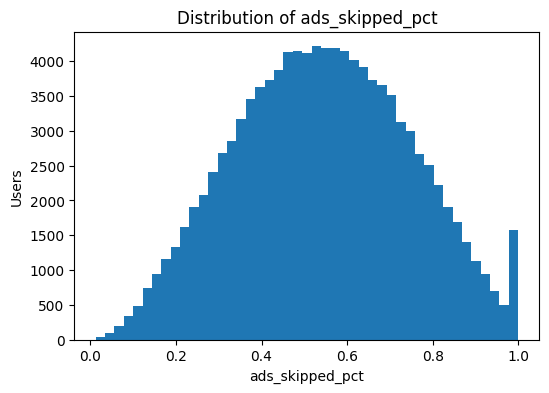

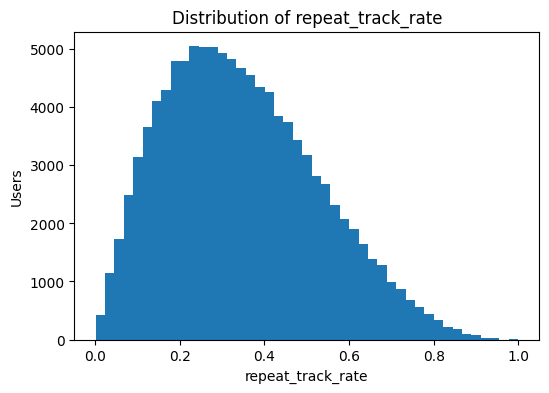

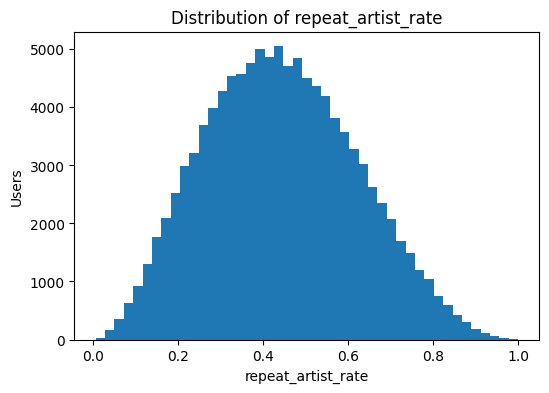

In [0]:
pct_feature=[
    "skip_rate",
    "liked_songs_pct",
    "ads_skipped_pct",
    "repeat_track_rate",
    "repeat_artist_rate"
]
for col in pct_feature:
    plt.figure(figsize=(6,4))
    plt.hist(
        spotify_user_behavior[col],
        bins=45
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Users")
    plt.show()


In [0]:
summary = (
    spotify_user_behavior[numeric_cols]
    .describe()
    .T
    .loc[:, ["mean", "std", "min",
             "25%", "50%", "75%", "max"]]
    .round(3)
)
summary["mean_minus_median"] = (
    summary["mean"] - summary["50%"]
).round(3)
summary.sort_values("mean_minus_median", ascending=False
).head(10)
print("\nTop 10 features by mean - median (skew indicator):")
print(
    summary
    .sort_values("mean_minus_median", ascending=False)
    .head(10)
)


Top 10 features by mean - median (skew indicator):
                      mean     std    min  ...    75%    max  mean_minus_median
artists_followed    15.969  77.937  1.000  ...  4.000  800.0             13.969
playlists_followed   9.165  42.990  1.000  ...  3.000  500.0              8.165
sessions_per_day     1.308   0.798  1.000  ...  1.000   15.0              0.308
skip_rate            0.326   0.179  0.001  ...  0.442    1.0              0.020
repeat_track_rate    0.347   0.180  0.001  ...  0.468    1.0              0.020

[5 rows x 8 columns]


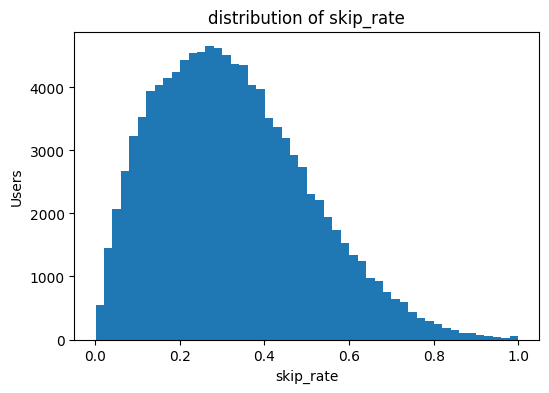

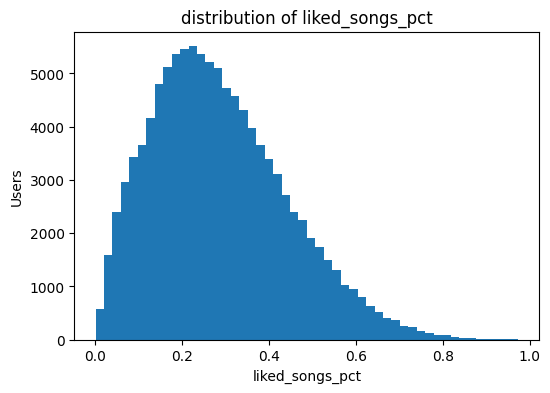

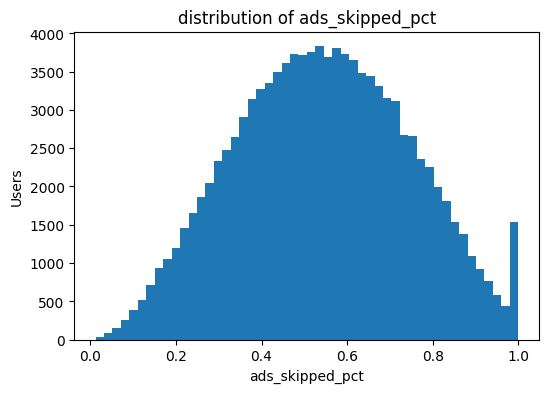

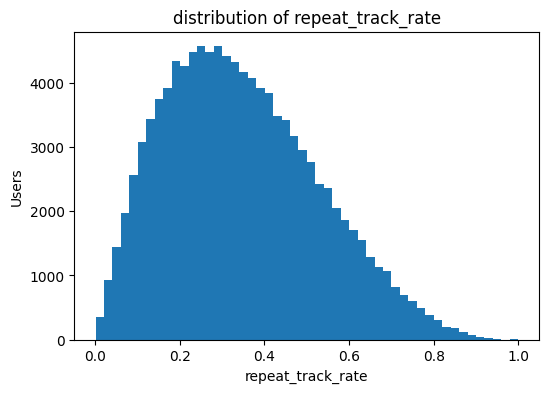

In [0]:
pct_features = [
    "skip_rate",
    "liked_songs_pct",
    "ads_skipped_pct",
    "repeat_track_rate"
]
for col in pct_features:
    plt.figure(figsize=(6, 4))
    plt.hist(
        spotify_user_behavior[col],
        bins=50
    )
    plt.title(f"distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Users")
    plt.show()

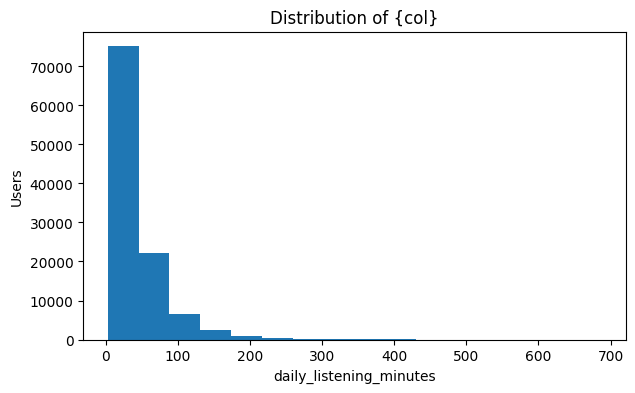

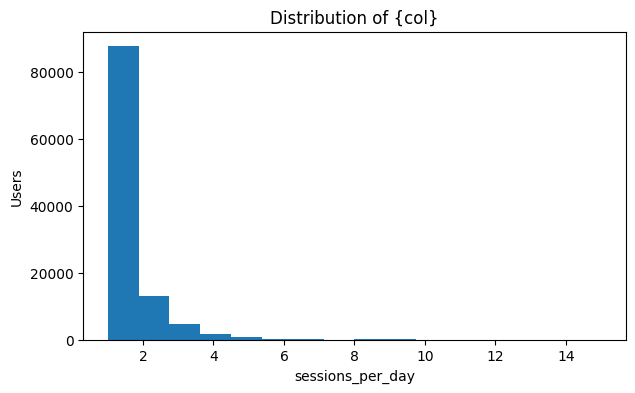

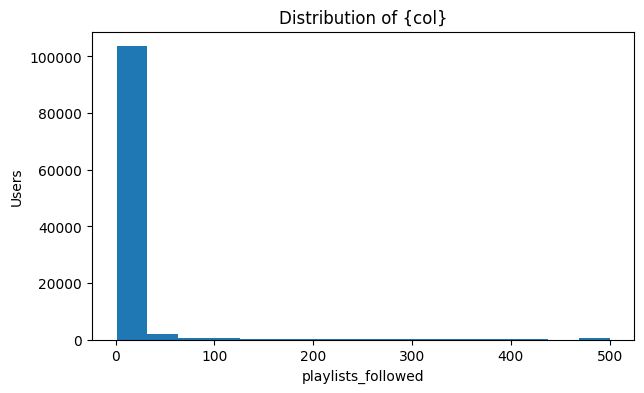

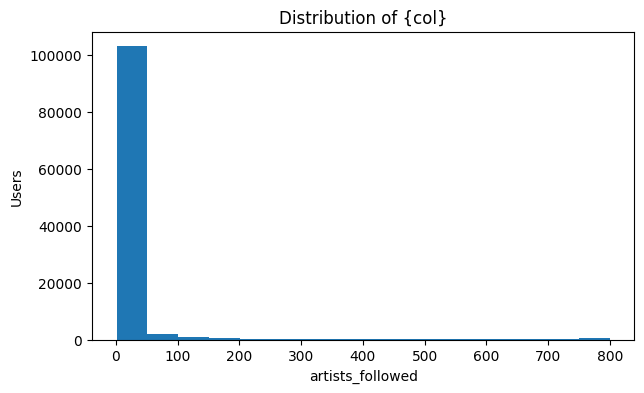

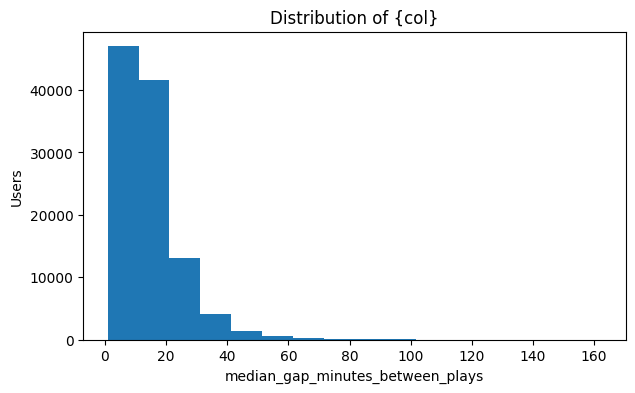

In [0]:
import matplotlib.pyplot as plt
features_to_plot=[
    "daily_listening_minutes",
    "sessions_per_day",
    "playlists_followed",
    "artists_followed",
    "median_gap_minutes_between_plays"
]

for col in features_to_plot:
    plt.figure(figsize=(7,4))
    plt.hist(spotify_user_behavior[col],
             bins=16)
    plt.title("Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Users")
    plt.show()

In [0]:
#Iteration 2 
#silhout_score


In [0]:
# Imports 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples


In [0]:
# g;obal display & plotting configuration 
sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)


In [0]:
#load spotify data (spark to pandas)
spotify_user_behavior = spark.table(
    "workspace.spotify. spotify_user_behavior"
).toPandas()
spotify_user_demo = spark.table(
    "workspace.spotify.spotify_user_demo"
).toPandas()
print("Behaviour shape:",  spotify_user_behavior.shape)
print("Demo shape:", spotify_user_demo.shape)


Behaviour shape: (108000, 26)
Demo shape: (108000, 6)


In [0]:
#manual features sselection (core behaviour axes)
CLUSTER_FEATURES_V1 = [
    "daily_listening_minutes",           
    "sessions_per_day",
    "days_active_last_30",                  
    "avg_session_minutes",                
    "skip_rate",                      
    "liked_songs_pct",                   
    "ads_skipped_pct",                        
]



In [0]:
#5) column existence validation (manaul, explicit)
missing_1 = "daily_listening_minutes" not in spotify_user_behavior.columns
missing_2 = "sessions_per_day" not in spotify_user_behavior.columns
missing_3 = "days_active_last_30" not in spotify_user_behavior.columns
missing_4 = "avg_session_minutes" not in spotify_user_behavior.columns
missing_5 = "skip_rate" not in spotify_user_behavior.columns
missing_6 = "liked_songs_pct" not in spotify_user_behavior.columns
missing_7 = "ads_skipped_pct" not in spotify_user_behavior.columns
if missing_1 or missing_2 or missing_3 or missing_4 or missing_5 or missing_6 or missing_7:
    missing_cols = []
    if missing_1: missing_cols.append("daily_listening_minutes")
    if missing_2: missing_cols.append("sessions_per_day")
    if missing_3: missing_cols.append("days_active_last_30")
    if missing_4: missing_cols.append("avg_session_minutes")
    if missing_5: missing_cols.append("skip_rate")
    if missing_6: missing_cols.append("liked_songs_pct")
    if missing_7: missing_cols.append("ads_skipped_pct")

    raise ValueError(f"Missing required columns: {missing_cols}")
 

6

In [0]:
base = spotify_user_behavior[["user_id"] + CLUSTER_FEATURES_V1].copy()

print("\nNull Check (selected features): ")
print(base[CLUSTER_FEATURES_V1].isnull().sum())


Null Check (selected features): 
daily_listening_minutes    0
sessions_per_day           0
days_active_last_30        0
avg_session_minutes        0
skip_rate                  0
liked_songs_pct            0
ads_skipped_pct            0
dtype: int64


In [0]:
#7) null check 
print("Null check (selected features):")
print(base[CLUSTER_FEATURES_V1].isnull().sum())

Null check (selected features):
daily_listening_minutes    0
sessions_per_day           0
days_active_last_30        0
avg_session_minutes        0
skip_rate                  0
liked_songs_pct            0
ads_skipped_pct            0
dtype: int64


In [0]:
print("\nRange check (pct features):")
print(f"{'skip_rate':16s} min={base['skip_rate'].min():.4f} max={base['skip_rate'].max():.4f}")
print(f"{'liked_songs_pct':16s} min={base['liked_songs_pct'].min():.4f} max={base['liked_songs_pct'].max():.4f}")
print(f"{'ads_skipped_pct':16s} min={base['ads_skipped_pct'].min():.4f} max={base['ads_skipped_pct'].max():.4f}")


Range check (pct features):
skip_rate        min=0.0006 max=1.0000
liked_songs_pct  min=0.0003 max=0.9737
ads_skipped_pct  min=0.0120 max=1.0000


In [0]:
#8) range sanity  check percentage feature

print("\nRange check (pct features):")
print(f"{'skip_rate':16s} min={base['skip_rate'].min():.4f} max={base['skip_rate'].max():.4f}")
print(f"{'liked_songs_pct':16s} min={base['liked_songs_pct'].min():.4f} max={base['liked_songs_pct'].max():.4f}")
print(f"{'ads_skipped_pct':16s} min={base['ads_skipped_pct'].min():.4f} max={base['ads_skipped_pct'].max():.4f}")


Range check (pct features):
skip_rate        min=0.0006 max=1.0000
liked_songs_pct  min=0.0003 max=0.9737
ads_skipped_pct  min=0.0120 max=1.0000


In [0]:
#9- 
before_rows = len(base)
base = base.dropna(subset=CLUSTER_FEATURES_V1)
after_rows = len(base)
if before_rows != after_rows:
    print(f"Dropped {before_rows - after_rows} rows due to nulls")

In [0]:
#10 set no of clusters
k = 4
#3-4 cluster are interpretable for business persons 

In [0]:
#11- build features matrix x 
X1 = base[CLUSTER_FEATURES_V1].copy()

In [0]:
#12 fit kmean
km1 = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20,
    max_iter=300
)
labels1  = km1.fit_predict(X1)
inertia1 = km1.inertia_


In [0]:
sil_avg_1 = silhouette_score(X1, labels1)

print("\nIteration 1 Results")
print("Inertia   :", round(inertia1, 2))
print("Silhouette:", round(sil_avg_1, 3))


Iteration 1 Results
Inertia   : 53703427.73
Silhouette: 0.515


In [0]:
base_iter1 = base.copy()
base_iter1["cluster"] = labels1

In [0]:
sizes1 = base_iter1["cluster"].value_counts().sort_index()

means1 = (
    base_iter1
    .groupby("cluster")[CLUSTER_FEATURES_V1]
    .mean()
    .round(3)
)

profile1 = means1.copy()
profile1.insert(0, "cluster_size", sizes1)

display(profile1)

cluster_size,daily_listening_minutes,sessions_per_day,days_active_last_30,avg_session_minutes,skip_rate,liked_songs_pct,ads_skipped_pct
64364,19.856434853443687,1.141,20.711689530042907,18.354081362562315,0.351,0.2744512332066867,0.5173755690419698
11069,107.96818663461094,1.742,22.183715219449827,77.59498633456487,0.287,0.3036627994667376,0.5998217329265335
1903,229.9233986688061,3.869,23.02739336393134,80.98213577608956,0.284,0.3178919587448702,0.5776118309132263
30664,53.237406679166924,1.342,21.656940217144875,44.33973725715372,0.289,0.30257552562529083,0.5769627874496115


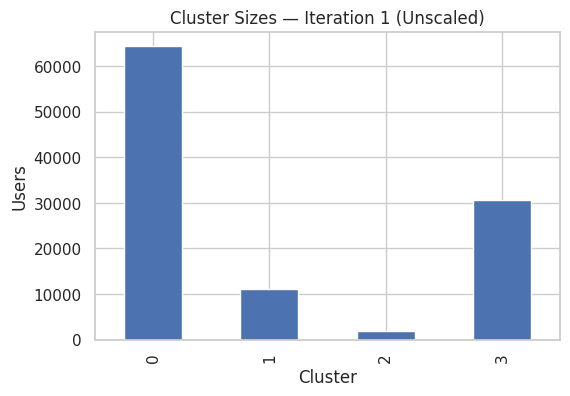

In [0]:
plt.figure(figsize=(6, 4))
base_iter1["cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Cluster Sizes — Iteration 1 (Unscaled)")
plt.xlabel("Cluster")
plt.ylabel("Users")
plt.show()

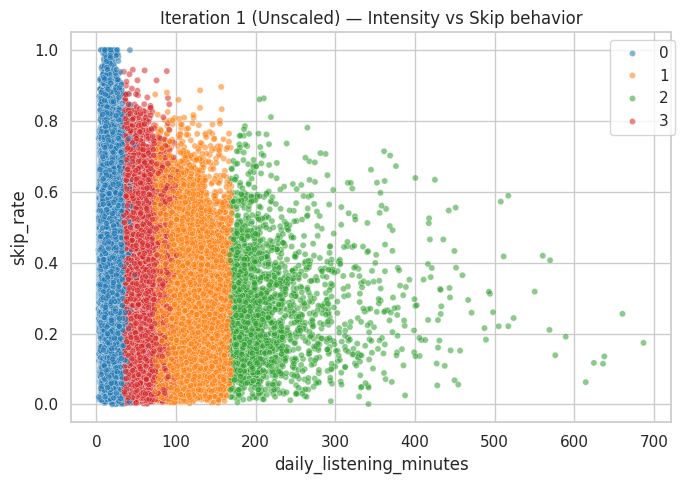

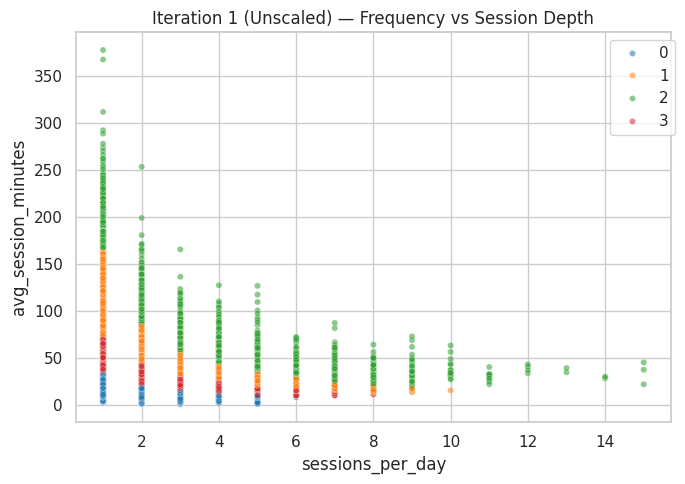

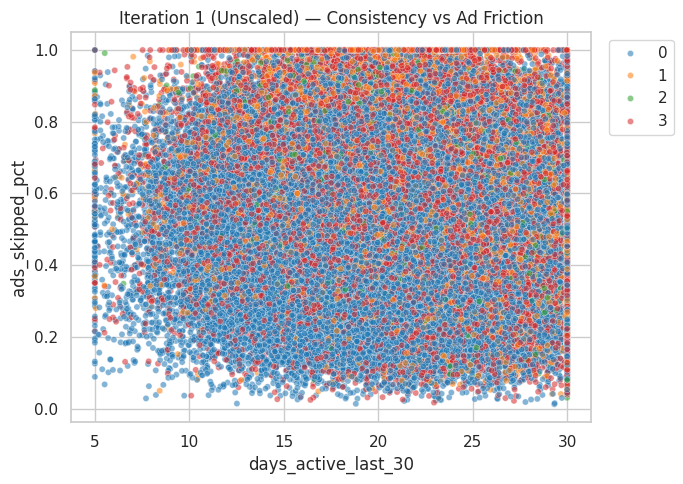

In [0]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter1,
    x="daily_listening_minutes",
    y="skip_rate",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55
)
plt.title("Iteration 1 (Unscaled) — Intensity vs Skip behavior")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# Frequency vs Session Depth
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter1,
    x="sessions_per_day",
    y="avg_session_minutes",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55
)
plt.title("Iteration 1 (Unscaled) — Frequency vs Session Depth")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# Consistency vs Ad Friction
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter1,
    x="days_active_last_30",
    y="ads_skipped_pct",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55
)
plt.title("Iteration 1 (Unscaled) — Consistency vs Ad Friction")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

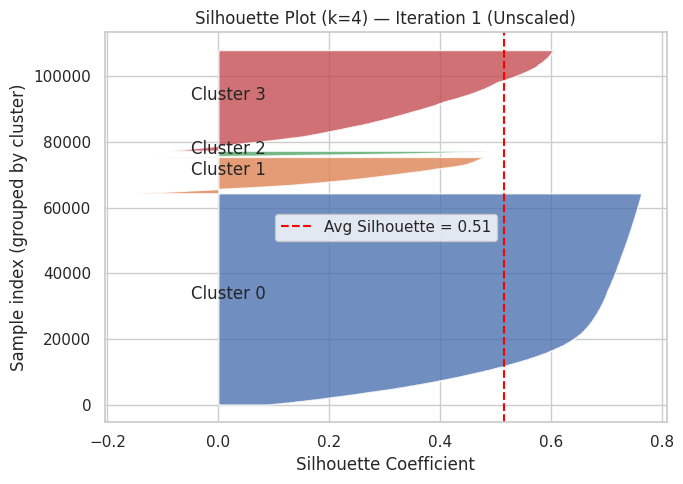

Iteration 1 Avg Silhouette: 0.515


In [0]:
# Step 1: Compute overall average silhouette score
# ------------------------------------------------------------
sil_avg_1 = silhouette_score(X1, labels1)
# Step 2: Compute silhouette score for EACH data point
# ------------------------------------------------------------
sil_values_1 = silhouette_samples(X1, labels1)
# Step 3: Initialize plotting canvas
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
# Step 4: Initialize vertical stacking pointer
# ------------------------------------------------------------
y_lower = 0
# Extract silhouette values belonging to Cluster 0
vals0 = sil_values_1[labels1 == 0]
# Sort values for visual smoothness
vals0.sort()
# Count number of points in Cluster 0
size0 = vals0.shape[0]
# Define upper boundary for cluster 0 band
y_upper = y_lower + size0
# Draw filled silhouette area for Cluster 0
plt.fill_betweenx(
    np.arange(y_lower, y_upper),  # vertical span
    0,                            # left boundary (silhouette = 0)
    vals0,                        # right boundary (actual silhouette values)
    alpha=0.8
)
# Label the cluster inside the band
plt.text(
    -0.05,                        # slightly left of zero
    y_lower + 0.5 * size0,        # vertically centered
    "Cluster 0"
)

# Update pointer for next cluster
y_lower = y_upper
# ============================================================
# CLUSTER 1
# ============================================================

vals1 = sil_values_1[labels1 == 1]
vals1.sort()
size1 = vals1.shape[0]
y_upper = y_lower + size1

plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals1, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size1, "Cluster 1")

y_lower = y_upper

# ============================================================
# CLUSTER 2
# ============================================================

vals2 = sil_values_1[labels1 == 2]
vals2.sort()
size2 = vals2.shape[0]
y_upper = y_lower + size2

plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals2, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size2, "Cluster 2")

y_lower = y_upper

# ============================================================
# CLUSTER 3
# ============================================================

vals3 = sil_values_1[labels1 == 3]
vals3.sort()
size3 = vals3.shape[0]
y_upper = y_lower + size3

plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals3, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size3, "Cluster 3")

y_lower = y_upper

# ------------------------------------------------------------
# Step 5: Draw average silhouette reference line
# ------------------------------------------------------------
plt.axvline(
    x=sil_avg_1,
    color="red",
    linestyle="--",
    label=f"Avg Silhouette = {sil_avg_1:.2f}"
)

# This vertical line represents overall clustering quality
# Clusters mostly to the RIGHT of this line are stronger

# ------------------------------------------------------------
# Step 6: Titles, labels, and rendering
# ------------------------------------------------------------
plt.title("Silhouette Plot (k=4) — Iteration 1 (Unscaled)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Sample index (grouped by cluster)")

# Y-axis label reminder:
# - This is NOT a real variable
# - It only represents stacked sample order

plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Step 7: Print numeric silhouette value for logging
# ------------------------------------------------------------
print("Iteration 1 Avg Silhouette:", round(sil_avg_1, 3))

